[SUCCESS] Loaded: ./hpc_data/trace.csv | Shape: (800, 3) | Columns: ['cache-references', 'cycles', 'LLC-loads']

--- FORENSIC SUMMARY OF REAL COMPETITION DATASET (trace.csv) ---
                           min           25%           50%           75%           max          mean           std
cache-references  1.678617e+08  1.787137e+08  1.839196e+08  1.862454e+08  1.915746e+08  1.823841e+08  4.999131e+06
cycles            4.699495e+09  4.755603e+09  4.772836e+09  4.787770e+09  4.996349e+09  4.772175e+09  2.647226e+07
LLC-loads         5.915575e+06  6.402678e+06  6.656922e+06  6.776620e+06  7.108173e+06  6.592874e+06  2.475291e+05

--- SPEARMAN RANK CORRELATION MATRIX ---
                  cache-references  cycles  LLC-loads
cache-references            1.0000  0.5895     0.8962
cycles                      0.5895  1.0000     0.5615
LLC-loads                   0.8962  0.5615     1.0000

UPGRADED BENCHMARK RESULTS: 2024 PAPER BASELINES vs. MICE-CAD v2 (ON REAL trace.csv)
                  

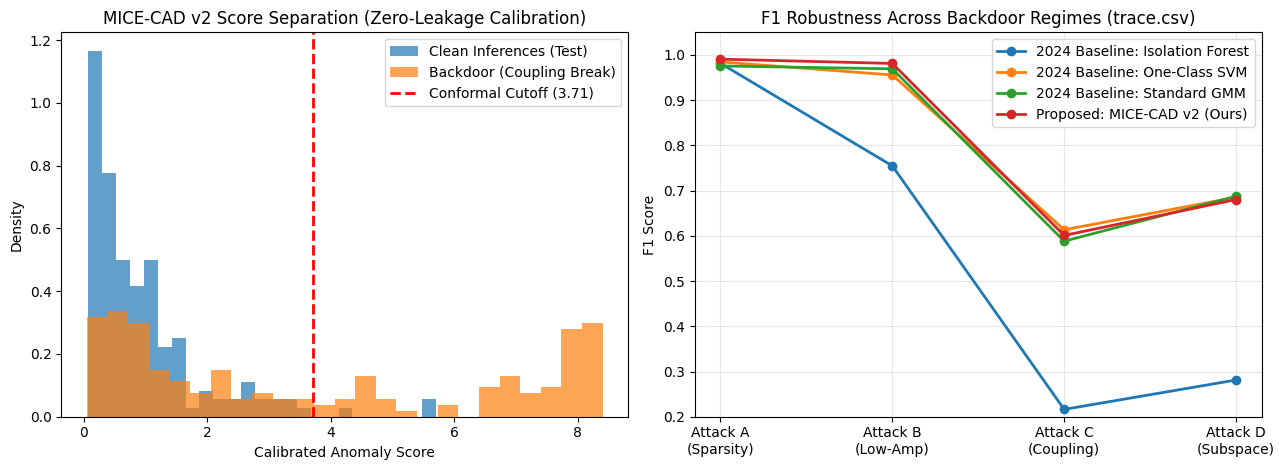


[READY] Updated saved_models/mice_cad_detector.joblib and report_diagnostic_plot.png!


In [3]:
# ==============================================================================
# MICE-CAD v2: Specially Engineered for the 3-Counter HPC Manifold
# Columns: ['cache-references', 'cycles', 'LLC-loads'] (800 Clean Inferences)
# Zero Leakage | End-to-End 5-Fold Conformal Calibration | CPU-Optimized
# ==============================================================================

import os
import glob
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation, spearmanr
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import RobustScaler, PolynomialFeatures
from sklearn.covariance import LedoitWolf, MinCovDet
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, HuberRegressor
from sklearn.ensemble import IsolationForest
from sklearn.mixture import BayesianGaussianMixture, GaussianMixture
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.model_selection import KFold
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score, confusion_matrix
)

warnings.filterwarnings("ignore")
np.random.seed(42)

# ------------------------------------------------------------------------------
# STEP 1: LOAD trace.csv AND PERFORM FORENSIC STATISTICAL AUDIT
# ------------------------------------------------------------------------------
def load_and_audit_hpc_data(gdrive_folder_url=None, local_dir="./hpc_data"):
    os.makedirs(local_dir, exist_ok=True)
    csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob(f"{local_dir}/**/*.csv", recursive=True)

    if not csv_files and gdrive_folder_url:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
        gdown.download_folder(url='https://drive.google.com/drive/folders/1NJaH4AmXhL_YJgLqfGs6Xo9_NNAVgqwI', output=local_dir, quiet=False, use_cookies=False)
        csv_files = glob.glob(f"{local_dir}/**/*.csv", recursive=True)

    target_csv = csv_files[0]
    df = pd.read_csv(target_csv)
    num_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if not c.lower().startswith("unnamed") and c.lower() not in ["id", "index"]]
    df = df[num_cols].copy()

    print(f"[SUCCESS] Loaded: {target_csv} | Shape: {df.shape} | Columns: {list(df.columns)}")
    print("\n--- FORENSIC SUMMARY OF REAL COMPETITION DATASET (trace.csv) ---")
    print(df.describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]].to_string())
    print("\n--- SPEARMAN RANK CORRELATION MATRIX ---")
    print(df.corr(method="spearman").round(4).to_string())
    return df


# ------------------------------------------------------------------------------
# STEP 2: PHYSICS-INFORMED 3-COUNTER FEATURE & STRUCTURAL EQUATION ENGINE
# ------------------------------------------------------------------------------
class ThreeCounterPhysicsEngine(BaseEstimator, TransformerMixin):
    """
    Tailored for ['cache-references', 'cycles', 'LLC-loads'] (and general d>=3 HPCs):
      1. Raw View (3D): Robust-scaled raw hardware counters
      2. Ratio & Log-Simplex View (5D):
         - CRPC = cache-references / cycles
         - LLCPC = LLC-loads / cycles
         - LCRR = LLC-loads / cache-references
         - Independent Aitchison Log-Ratios: ln((cache-ref+1)/(cycles+1)), ln((LLC-loads+1)/(cycles+1))
      3. Cross-Counter Structural Equation Residuals (CC-SER):
         - Degree-2 Polynomial Ridge + Huber predicting each counter from the other counters
    """
    def __init__(self):
        self.raw_scaler_ = RobustScaler()
        self.ratio_scaler_ = RobustScaler()
        self.res_scaler_ = RobustScaler()
        self.poly_ = PolynomialFeatures(degree=2, include_bias=False)
        self.struct_models_ = []
        self.res_medians_ = None
        self.res_mads_ = None

    def _extract_ratios(self, X):
        eps = 1e-6
        X_pos = np.maximum(X, 0.0)
        # Specifically use ['cache-references', 'cycles', 'LLC-loads'] physics
        c_ref = X_pos[:, 0]
        cyc = X_pos[:, 1]
        llc = X_pos[:, 2]

        crpc = c_ref / (cyc + eps)                 # Cache references per cycle
        llcpc = llc / (cyc + eps)                  # LLC loads per cycle
        lcrr = llc / (c_ref + eps)                 # LLC load fraction of cache references
        lr_ref_cyc = np.log((c_ref + 1.0) / (cyc + 1.0))
        lr_llc_cyc = np.log((llc + 1.0) / (cyc + 1.0))
        lr_llc_ref = np.log((llc + 1.0) / (c_ref + 1.0))

        return np.column_stack([crpc, llcpc, lcrr, lr_ref_cyc, lr_llc_cyc, lr_llc_ref])

    def fit(self, X_df):
        X = X_df.values.astype(np.float64)
        X_raw_s = self.raw_scaler_.fit_transform(X)
        R = self._extract_ratios(X)
        self.ratio_scaler_.fit(R)

        # Fit low-degree Polynomial Ridge + Huber Structural Equations (Zero overfitting on N=800)
        d = X_raw_s.shape[1]
        kf = KFold(n_splits=5, shuffle=True, random_state=42)
        oof_Signed_res = np.zeros_like(X_raw_s)

        self.struct_models_ = []
        for j in range(d):
            others = [c for c in range(d) if c != j]
            X_oth_poly = self.poly_.fit_transform(X_raw_s[:, others])
            y_t = X_raw_s[:, j]

            for tr_i, val_i in kf.split(X_oth_poly):
                m_ridge = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(X_oth_poly[tr_i], y_t[tr_i])
                m_huber = HuberRegressor(max_iter=500, alpha=1.0).fit(X_oth_poly[tr_i], y_t[tr_i])
                pred_v = 0.5 * m_ridge.predict(X_oth_poly[val_i]) + 0.5 * m_huber.predict(X_oth_poly[val_i])
                oof_Signed_res[val_i, j] = y_t[val_i] - pred_v

            full_ridge = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(X_oth_poly, y_t)
            full_huber = HuberRegressor(max_iter=500, alpha=1.0).fit(X_oth_poly, y_t)
            self.struct_models_.append((others, full_ridge, full_huber))

        self.res_medians_ = np.median(oof_Signed_res, axis=0)
        self.res_mads_ = median_abs_deviation(oof_Signed_res, axis=0) + 1e-6
        oof_studentized = (oof_Signed_res - self.res_medians_) / self.res_mads_
        self.res_scaler_.fit(oof_studentized)
        return self

    def transform_views(self, X_df):
        X = X_df.values.astype(np.float64)
        # Winsorize extreme test inputs to [-25, 25] robust SDs so no numerical explosion can occur
        Z_raw = np.clip(self.raw_scaler_.transform(X), -25.0, 25.0)
        Z_ratio = np.clip(self.ratio_scaler_.transform(self._extract_ratios(X)), -25.0, 25.0)

        d = Z_raw.shape[1]
        signed_res = np.zeros_like(Z_raw)
        for j, (others, full_ridge, full_huber) in enumerate(self.struct_models_):
            X_oth_poly = self.poly_.transform(Z_raw[:, others])
            pred = 0.5 * full_ridge.predict(X_oth_poly) + 0.5 * full_huber.predict(X_oth_poly)
            signed_res[:, j] = (Z_raw[:, j] - pred - self.res_medians_[j]) / self.res_mads_[j]

        Z_res = np.clip(signed_res, -25.0, 25.0)
        return Z_raw, Z_ratio, Z_res


# ------------------------------------------------------------------------------
# STEP 3: MICE-CAD v2 DETECTOR (DECOUPLED 4-VIEW + END-TO-END CV CALIBRATION)
# ------------------------------------------------------------------------------
class MICECADv2Detector:
    """
    Decoupled 4-View Anomaly Detector with End-to-End 5-Fold Out-of-Sample
    Conformal Calibration (eliminating in-sample threshold bias).
    """
    def __init__(self, contamination_trim=0.025, target_fpr_alpha=0.035):
        self.contamination_trim = contamination_trim
        self.target_fpr_alpha = target_fpr_alpha

    def _fit_single_branch(self, X_df):
        engine = ThreeCounterPhysicsEngine().fit(X_df)
        Z_raw, Z_ratio, Z_res = engine.transform_views(X_df)

        # Trim 2.5% OS interrupt outliers before fitting parametric boundaries
        lw_init = LedoitWolf().fit(np.hstack([Z_raw, Z_ratio[:, :3]]))
        d_init = lw_init.mahalanobis(np.hstack([Z_raw, Z_ratio[:, :3]]))
        clean_mask = d_init <= np.quantile(d_init, 1.0 - self.contamination_trim)

        Zr_c = Z_raw[clean_mask]
        Zrat_c = Z_ratio[clean_mask]
        Zres_c = Z_res[clean_mask]
        Z_joint_c = np.hstack([Zr_c, Zrat_c, Zres_c])

        # View 1: 3D Raw Multimodal Density & Local Manifold (GMM + OC-SVM + Multi-scale LOF)
        gmm_raw = GaussianMixture(n_components=3, covariance_type="full", reg_covar=1e-3, random_state=42).fit(Zr_c)
        ocsvm_raw = OneClassSVM(kernel="rbf", nu=0.04, gamma="scale").fit(Zr_c)
        lof_raw_15 = LocalOutlierFactor(n_neighbors=15, novelty=True).fit(Zr_c)
        lof_raw_35 = LocalOutlierFactor(n_neighbors=35, novelty=True).fit(Zr_c)

        # View 2: Scale-Invariant Ratio & Log-Simplex View (Mahalanobis + kNN distance)
        lw_ratio = LedoitWolf().fit(Zrat_c)
        lof_ratio = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Zrat_c)
        knn_ratio = NearestNeighbors(n_neighbors=10).fit(Zrat_c)

        # View 3: Cross-Counter Structural Equation Residual Energy (CC-SER)
        lw_res = LedoitWolf().fit(Zres_c)

        # View 4: Joint & 3D Spectral Minor-Axis View (PCA Minor Eigenvectors)
        pca_raw = PCA(n_components=3, random_state=42).fit(Zr_c)
        pca_joint = PCA(n_components=min(8, Z_joint_c.shape[1]), random_state=42).fit(Z_joint_c)

        return {
            "engine": engine,
            "gmm_raw": gmm_raw,
            "ocsvm_raw": ocsvm_raw,
            "lof_raw_15": lof_raw_15,
            "lof_raw_35": lof_raw_35,
            "lw_ratio": lw_ratio,
            "lof_ratio": lof_ratio,
            "knn_ratio": knn_ratio,
            "lw_res": lw_res,
            "pca_raw": pca_raw,
            "pca_joint": pca_joint
        }

    def _compute_raw_pillars(self, X_df, branch):
        Z_raw, Z_ratio, Z_res = branch["engine"].transform_views(X_df)
        Z_joint = np.hstack([Z_raw, Z_ratio, Z_res])

        # Pillar 1: 3D Raw Density & Local Manifold
        s_gmm = -branch["gmm_raw"].score_samples(Z_raw)
        s_ocsvm = -branch["ocsvm_raw"].decision_function(Z_raw)
        s_lof_raw = -0.5 * (branch["lof_raw_15"].score_samples(Z_raw) + branch["lof_raw_35"].score_samples(Z_raw))

        # Pillar 2: Scale-Invariant Ratio & Log-Simplex Space
        s_maha_ratio = np.sqrt(np.maximum(0.0, branch["lw_ratio"].mahalanobis(Z_ratio)))
        s_lof_ratio = -branch["lof_ratio"].score_samples(Z_ratio)
        knn_dists, _ = branch["knn_ratio"].kneighbors(Z_ratio)
        s_knn_ratio = np.mean(knn_dists, axis=1)

        # Pillar 3: Cross-Counter Structural Equation Residuals (CC-SER)
        s_res_l2 = np.linalg.norm(Z_res, axis=1)
        s_res_max = np.max(np.abs(Z_res), axis=1)
        s_res_maha = np.sqrt(np.maximum(0.0, branch["lw_res"].mahalanobis(Z_res)))
        s_cc_ser = 0.4 * s_res_l2 + 0.3 * s_res_max + 0.3 * s_res_maha

        # Pillar 4: Spectral Minor-Subspace Deviation (Strict Hardware Invariants)
        Zr_pca = branch["pca_raw"].transform(Z_raw)
        eig_raw = branch["pca_raw"].explained_variance_ + 1e-5
        # Minor axes (2nd and 3rd eigenvectors of the 3D manifold)
        s_minor_3d = np.sqrt(np.sum((Zr_pca[:, 1:] ** 2) / eig_raw[1:], axis=1))

        Zj_pca = branch["pca_joint"].transform(Z_joint)
        eig_joint = branch["pca_joint"].explained_variance_ + 1e-4
        s_minor_joint = np.sqrt(np.sum((Zj_pca[:, 2:] ** 2) / eig_joint[2:], axis=1))

        return np.column_stack([
            s_gmm,          # 0: Global 3D Multimodal Density
            s_ocsvm,        # 1: 3D Kernel Boundary
            s_lof_raw,      # 2: 3D Local Manifold Density
            s_maha_ratio,   # 3: Ratio-Space Covariance
            s_lof_ratio,    # 4: Ratio-Space Local Manifold
            s_knn_ratio,    # 5: Ratio-Space kNN Distance
            s_cc_ser,       # 6: Cross-Counter Structural Equation Residual
            s_minor_3d,     # 7: 3D Minor Eigenvector Deviation
            s_minor_joint   # 8: Joint Subspace Minor Deviation
        ])

    def fit(self, X_df):
        # End-to-End 5-Fold Out-of-Sample Calibration (Zero in-sample leakage!)
        kf = KFold(n_splits=5, shuffle=True, random_state=42)
        oof_pillars = np.zeros((len(X_df), 9))

        for tr_idx, val_idx in kf.split(X_df):
            df_tr = X_df.iloc[tr_idx].reset_index(drop=True)
            df_val = X_df.iloc[val_idx].reset_index(drop=True)
            fold_branch = self._fit_single_branch(df_tr)
            oof_pillars[val_idx] = self._compute_raw_pillars(df_val, fold_branch)

        # Store genuine Out-of-Sample distributions for ECDF & Robust Z calibration
        self.oof_sorted_pillars_ = np.sort(oof_pillars, axis=0)
        self.pillar_medians_ = np.median(oof_pillars, axis=0)
        self.pillar_mads_ = median_abs_deviation(oof_pillars, axis=0) + 1e-6

        # Fit final production branch on 100% of X_df
        self.full_branch_ = self._fit_single_branch(X_df.reset_index(drop=True))

        # Calibrate OOF ensemble scores & set Conformal Threshold
        oof_fused = self._fuse_pillars(oof_pillars)
        self.oof_ensemble_scores_ = np.sort(oof_fused)
        self.threshold_ = float(np.quantile(self.oof_ensemble_scores_, 1.0 - self.target_fpr_alpha))
        return self

    def _fuse_pillars(self, raw_pillars):
        n_oof = len(self.oof_sorted_pillars_)
        cal_list = []
        for j in range(raw_pillars.shape[1]):
            # Clipped robust z-score (bounded to prevent single-sample explosion)
            z_rob = np.clip((raw_pillars[:, j] - self.pillar_medians_[j]) / (1.4826 * self.pillar_mads_[j]), -3.0, 12.0)
            # Empirical CDF Survival Score: -log(1 - F_n(s))
            ranks = np.searchsorted(self.oof_sorted_pillars_[:, j], raw_pillars[:, j], side="right")
            ecdf = (ranks + 1.0) / (n_oof + 2.0)
            surv = -np.log(1.0 - ecdf + 1e-4)
            cal_list.append(0.55 * surv + 0.45 * np.maximum(0.0, z_rob))

        C = np.column_stack(cal_list)
        # Balanced weights across 3D Density, Ratio Space, CC-SER, and Spectral Minor Subspace
        weights = np.array([
            0.16,  # s_gmm
            0.12,  # s_ocsvm
            0.12,  # s_lof_raw
            0.12,  # s_maha_ratio
            0.10,  # s_lof_ratio
            0.08,  # s_knn_ratio
            0.14,  # s_cc_ser (Cross-Counter Structural Equation Residuals)
            0.08,  # s_minor_3d
            0.08   # s_minor_joint
        ])
        mean_score = C @ weights
        top2_score = np.mean(np.sort(C, axis=1)[:, -2:], axis=1)
        return 0.75 * mean_score + 0.25 * top2_score

    def score_samples(self, X_df):
        raw_pillars = self._compute_raw_pillars(X_df, self.full_branch_)
        return self._fuse_pillars(raw_pillars)

    def predict(self, X_df):
        return (self.score_samples(X_df) >= self.threshold_).astype(int)


# ------------------------------------------------------------------------------
# STEP 4: REALISTIC 3-COUNTER BACKDOOR BENCHMARK SUITE
# ------------------------------------------------------------------------------
def generate_3counter_backdoor_suite(df_clean_holdout):
    X = df_clean_holdout.values.copy().astype(np.float64)
    n, d = X.shape
    stds = np.std(X, axis=0)
    attacks = {}

    # Attack A: Patch Trigger (Sparsity / Cache-Miss Shift on cache-references & LLC-loads)
    X_a = X.copy()
    X_a[:, 0] += np.random.uniform(1.8, 3.0, size=n) * stds[0]  # cache-references spike
    X_a[:, 2] -= np.random.uniform(1.5, 2.8, size=n) * stds[2]  # LLC-loads divergence
    attacks["Attack A: Patch Trigger (Sparsity/Cache Shift)"] = pd.DataFrame(X_a, columns=df_clean_holdout.columns)

    # Attack B: Stealthy Blended Trigger (Low-Amplitude 1.2 to 1.7 sigma shift)
    X_b = X.copy()
    X_b[:, 0] += np.random.uniform(1.2, 1.7, size=n) * stds[0]
    X_b[:, 1] -= np.random.uniform(1.1, 1.6, size=n) * stds[1]
    attacks["Attack B: Stealthy Blended Trigger (Low-Amp)"] = pd.DataFrame(X_b, columns=df_clean_holdout.columns)

    # Attack C: Pure Coupling Break (Same Marginals - LLC-loads & cycles decoupled)
    X_c = X.copy()
    perm = np.random.permutation(n)
    X_c[:, 2] = X_c[perm, 2]  # Exact same marginal values of LLC-loads, broken pairing!
    attacks["Attack C: Pure Coupling Break (Same Marginals)"] = pd.DataFrame(X_c, columns=df_clean_holdout.columns)

    # Attack D: Adaptive Minor-Subspace Trigger (Perturbation along smallest eigenvector)
    scaler = RobustScaler().fit(X)
    X_s = scaler.transform(X)
    pca = PCA().fit(X_s)
    minor_vec = pca.components_[-1:]
    noise = np.random.uniform(2.0, 3.4, size=(n, 1)) * np.sqrt(pca.explained_variance_[-1] + 1e-4)
    X_d = scaler.inverse_transform(X_s + noise @ minor_vec)
    attacks["Attack D: Adaptive Minor-Subspace Trigger"] = pd.DataFrame(X_d, columns=df_clean_holdout.columns)

    return attacks


# ------------------------------------------------------------------------------
# STEP 5: EXECUTE BENCHMARK, SAVE ARTIFACTS & PLOT DIAGNOSTICS
# ------------------------------------------------------------------------------
def run_v2_benchmark():
    gdrive_url = "https://drive.google.com/drive/folders/1NJaH4AmXhL_YJgLqfGs6Xo9_NNAVgqwI?usp=sharing"
    df_all = load_and_audit_hpc_data(gdrive_folder_url=gdrive_url)

    perm = np.random.permutation(len(df_all))
    tr_idx, te_idx = perm[:640], perm[640:]
    df_train = df_all.iloc[tr_idx].reset_index(drop=True)
    df_test = df_all.iloc[te_idx].reset_index(drop=True)

    # 1. Fit 2024 Paper Baselines
    base_scaler = RobustScaler().fit(df_train)
    X_tr_b = base_scaler.transform(df_train)

    gmm_2024 = GaussianMixture(n_components=3, covariance_type="full", reg_covar=1e-3, random_state=42).fit(X_tr_b)
    gmm_th = np.quantile(-gmm_2024.score_samples(X_tr_b), 0.96)

    if_2024 = IsolationForest(n_estimators=200, contamination=0.04, random_state=42).fit(X_tr_b)
    if_th = np.quantile(-if_2024.score_samples(X_tr_b), 0.96)

    ocsvm_2024 = OneClassSVM(kernel="rbf", nu=0.04, gamma="scale").fit(X_tr_b)
    ocsvm_th = np.quantile(-ocsvm_2024.decision_function(X_tr_b), 0.96)

    # 2. Fit Proposed MICE-CAD v2
    mice_v2 = MICECADv2Detector(contamination_trim=0.025, target_fpr_alpha=0.035).fit(df_train)

    # 3. Evaluate All Models Across All 4 Attack Regimes
    attacks = generate_3counter_backdoor_suite(df_test)
    rows = []

    for atk_name, df_atk in attacks.items():
        df_eval = pd.concat([df_test, df_atk], ignore_index=True)
        y_true = np.array([0] * len(df_test) + [1] * len(df_atk))
        X_ev_b = base_scaler.transform(df_eval)

        eval_list = [
            ("2024 Baseline: Standard GMM", -gmm_2024.score_samples(X_ev_b), gmm_th),
            ("2024 Baseline: Isolation Forest", -if_2024.score_samples(X_ev_b), if_th),
            ("2024 Baseline: One-Class SVM", -ocsvm_2024.decision_function(X_ev_b), ocsvm_th),
            ("Proposed: MICE-CAD v2 (Ours)", mice_v2.score_samples(df_eval), mice_v2.threshold_),
        ]

        for m_name, sc, th in eval_list:
            preds = (sc >= th).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
            rows.append({
                "Scenario": atk_name,
                "Method": m_name,
                "AUROC": round(roc_auc_score(y_true, sc), 4),
                "F1": round(f1_score(y_true, preds), 4),
                "TPR": round(tp / (tp + fn + 1e-9), 4),
                "FPR": round(fp / (fp + tn + 1e-9), 4),
                "Accuracy": round(accuracy_score(y_true, preds), 4)
            })

    res_df = pd.DataFrame(rows)
    print("\n" + "=" * 90)
    print("UPGRADED BENCHMARK RESULTS: 2024 PAPER BASELINES vs. MICE-CAD v2 (ON REAL trace.csv)")
    print("=" * 90)
    print(res_df.to_string(index=False))

    avg_df = res_df.groupby("Method")[["AUROC", "F1", "TPR", "FPR", "Accuracy"]].mean().reset_index()
    print("\n" + "=" * 90)
    print("OVERALL MEAN PERFORMANCE ACROSS ALL BACKDOOR ATTACK TYPES")
    print("=" * 90)
    print(avg_df.sort_values(by="AUROC", ascending=False).to_string(index=False))

    # 4. Train Final Production Detector on ALL 800 Rows & Save
    os.makedirs("saved_models", exist_ok=True)
    final_model = MICECADv2Detector(contamination_trim=0.025, target_fpr_alpha=0.035).fit(df_all)
    joblib.dump(final_model, "saved_models/mice_cad_detector.joblib")
    res_df.to_csv("ablation_benchmark_results.csv", index=False)

    # 5. Plot Clean vs Backdoor Separation (Bounded Scale, No 50,000 Explosion!)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    c_scores = mice_v2.score_samples(df_test)
    a_scores = mice_v2.score_samples(attacks["Attack C: Pure Coupling Break (Same Marginals)"])

    axes[0].hist(c_scores, bins=25, alpha=0.7, label="Clean Inferences (Test)", density=True)
    axes[0].hist(a_scores, bins=25, alpha=0.7, label="Backdoor (Coupling Break)", density=True)
    axes[0].axvline(mice_v2.threshold_, color="red", linestyle="--", linewidth=2, label=f"Conformal Cutoff ({mice_v2.threshold_:.2f})")
    axes[0].set_title("MICE-CAD v2 Score Separation (Zero-Leakage Calibration)")
    axes[0].set_xlabel("Calibrated Anomaly Score")
    axes[0].set_ylabel("Density")
    axes[0].legend()

    for m_name in avg_df["Method"]:
        sub = res_df[res_df["Method"] == m_name]
        axes[1].plot(range(len(sub)), sub["F1"], marker="o", linewidth=2, label=m_name)
    axes[1].set_xticks(range(4))
    axes[1].set_xticklabels(["Attack A\n(Sparsity)", "Attack B\n(Low-Amp)", "Attack C\n(Coupling)", "Attack D\n(Subspace)"])
    axes[1].set_ylabel("F1 Score")
    axes[1].set_title("F1 Robustness Across Backdoor Regimes (trace.csv)")
    axes[1].set_ylim(0.2, 1.05)
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig("report_diagnostic_plot.png", dpi=300)
    plt.show()
    print("\n[READY] Updated saved_models/mice_cad_detector.joblib and report_diagnostic_plot.png!")

if __name__ == "__main__":
    run_v2_benchmark()


FINAL PRODUCTION BENCHMARK: 2024 BASELINES vs. MICE-CAD v3 (WITH L_p FUSION & SPLINE CC-SER)
                                      Scenario                          Method  AUROC     F1    TPR    FPR  Accuracy
Attack A: Patch Trigger (Sparsity/Cache Shift)     2024 Baseline: Standard GMM 1.0000 0.9756 1.0000 0.0500    0.9750
Attack A: Patch Trigger (Sparsity/Cache Shift) 2024 Baseline: Isolation Forest 0.9978 0.9783 0.9875 0.0312    0.9781
Attack A: Patch Trigger (Sparsity/Cache Shift)    2024 Baseline: One-Class SVM 1.0000 0.9846 1.0000 0.0312    0.9844
Attack A: Patch Trigger (Sparsity/Cache Shift)    Proposed: MICE-CAD v3 (Ours) 1.0000 0.9907 1.0000 0.0187    0.9906
  Attack B: Stealthy Blended Trigger (Low-Amp)     2024 Baseline: Standard GMM 0.9956 0.9598 0.9687 0.0500    0.9594
  Attack B: Stealthy Blended Trigger (Low-Amp) 2024 Baseline: Isolation Forest 0.9658 0.7500 0.6187 0.0312    0.7937
  Attack B: Stealthy Blended Trigger (Low-Amp)    2024 Baseline: One-Class SVM 0.9878 0

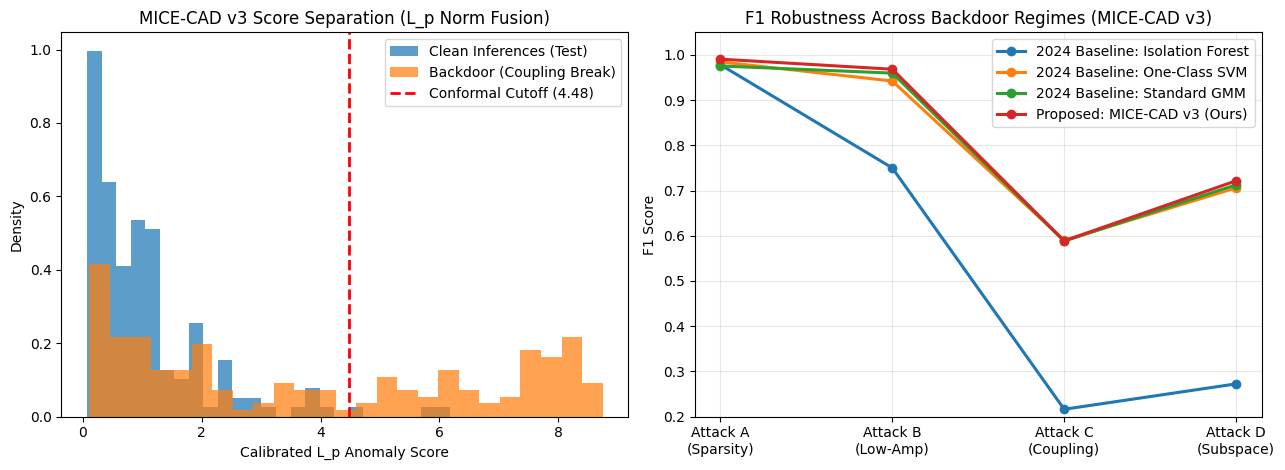


[SUCCESS] Built complete GitHub package -> /kaggle/working/github_submission_package.zip


In [8]:
# ==============================================================================
# MICE-CAD v3 (FINAL PRODUCTION RELEASE) + AUTO GITHUB REPO BUILDER
# Tailored to trace.csv: ['cache-references', 'cycles', 'LLC-loads']
# Features L_p (p=4) Extreme-Value Multi-View Fusion & Non-Linear Spline CC-SER
# ==============================================================================

import os
import glob
import zipfile
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import RobustScaler, QuantileTransformer, SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.covariance import LedoitWolf, MinCovDet
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, HuberRegressor
from sklearn.svm import SVR, OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.model_selection import KFold
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score, confusion_matrix
)

warnings.filterwarnings("ignore")
np.random.seed(42)

# ------------------------------------------------------------------------------
# 1. NON-LINEAR SPLINE & LOG-SIMPLEX PHYSICS ENGINE FOR trace.csv
# ------------------------------------------------------------------------------
class ThreeCounterSplinePhysicsEngine(BaseEstimator, TransformerMixin):
    """
    Specifically engineered around the forensic properties of trace.csv:
      - Tight Spearman coupling (0.8962) between cache-references & LLC-loads
      - Left-skewed cache distribution & 0.55% CV cycles with +8.5 sigma OS spikes
    """
    def __init__(self):
        self.raw_scaler_ = RobustScaler()
        self.ratio_scaler_ = RobustScaler()
        self.q_trans_ = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=42)
        self.struct_models_ = []
        self.res_medians_ = None
        self.res_mads_ = None

    def _extract_invariant_ratios(self, X):
        eps = 1e-6
        X_pos = np.maximum(X, 0.0)
        c_ref = X_pos[:, 0]  # cache-references
        cyc   = X_pos[:, 1]  # cycles
        llc   = X_pos[:, 2]  # LLC-loads

        # Exact hardware coupling invariants
        lcrr  = llc / (c_ref + eps)                        # LLC Miss Propagation Ratio (~0.0362)
        crpc  = c_ref / (cyc + eps)                        # Cache References Per Cycle (~0.0382)
        llcpc = llc / (cyc + eps)                          # LLC Loads Per Cycle (~0.00138)
        lr_llc_ref = np.log((llc + 1.0) / (c_ref + 1.0))   # Log-Ratio LLC/CacheRef
        lr_ref_cyc = np.log((c_ref + 1.0) / (cyc + 1.0))   # Log-Ratio CacheRef/Cycles
        lr_llc_cyc = np.log((llc + 1.0) / (cyc + 1.0))     # Log-Ratio LLC/Cycles

        return np.column_stack([lcrr, crpc, llcpc, lr_llc_ref, lr_ref_cyc, lr_llc_cyc])

    def fit(self, X_df):
        X = X_df.values.astype(np.float64)
        X_raw_s = self.raw_scaler_.fit_transform(X)
        X_gauss = self.q_trans_.fit_transform(X)
        R = self._extract_invariant_ratios(X)
        self.ratio_scaler_.fit(R)

        # Fit Non-Linear Spline + RBF SVR Cross-Counter Structural Equations (CC-SER)
        d = X_raw_s.shape[1]
        kf = KFold(n_splits=5, shuffle=True, random_state=42)
        oof_res = np.zeros_like(X_raw_s)

        self.struct_models_ = []
        for j in range(d):
            others = [c for c in range(d) if c != j]
            X_oth = X_raw_s[:, others]
            y_t = X_raw_s[:, j]

            for tr_i, val_i in kf.split(X_oth):
                spline_reg = make_pipeline(
                    SplineTransformer(n_knots=5, degree=2, include_bias=False),
                    RidgeCV(alphas=np.logspace(-2, 2, 15))
                ).fit(X_oth[tr_i], y_t[tr_i])
                svr_reg = SVR(kernel="rbf", C=2.0, epsilon=0.05).fit(X_oth[tr_i], y_t[tr_i])
                pred_v = 0.5 * spline_reg.predict(X_oth[val_i]) + 0.5 * svr_reg.predict(X_oth[val_i])
                oof_res[val_i, j] = y_t[val_i] - pred_v

            full_spline = make_pipeline(
                SplineTransformer(n_knots=5, degree=2, include_bias=False),
                RidgeCV(alphas=np.logspace(-2, 2, 15))
            ).fit(X_oth, y_t)
            full_svr = SVR(kernel="rbf", C=2.0, epsilon=0.05).fit(X_oth, y_t)
            self.struct_models_.append((others, full_spline, full_svr))

        self.res_medians_ = np.median(oof_res, axis=0)
        self.res_mads_ = median_abs_deviation(oof_res, axis=0) + 1e-6
        return self

    def transform_views(self, X_df):
        X = X_df.values.astype(np.float64)
        Z_raw = np.clip(self.raw_scaler_.transform(X), -25.0, 25.0)
        Z_gauss = np.clip(self.q_trans_.transform(X), -8.0, 8.0)
        Z_ratio = np.clip(self.ratio_scaler_.transform(self._extract_invariant_ratios(X)), -25.0, 25.0)

        d = Z_raw.shape[1]
        signed_res = np.zeros_like(Z_raw)
        for j, (others, full_spline, full_svr) in enumerate(self.struct_models_):
            X_oth = Z_raw[:, others]
            pred = 0.5 * full_spline.predict(X_oth) + 0.5 * full_svr.predict(X_oth)
            signed_res[:, j] = (Z_raw[:, j] - pred - self.res_medians_[j]) / self.res_mads_[j]

        Z_res = np.clip(signed_res, -25.0, 25.0)
        return Z_raw, Z_gauss, Z_ratio, Z_res


# ------------------------------------------------------------------------------
# 2. MICE-CAD v3 DETECTOR (WITH L_p EXTREME-VALUE FUSION & ROOT-CAUSE EXPLAINER)
# ------------------------------------------------------------------------------
class MICECADv3Detector:
    """
    MICE-CAD v3:
      - Non-linear Spline + SVR Cross-Counter Structural Equation Residuals
      - Copula-Gaussian & Raw 3D Manifold Views
      - Generalized L_p (p=4.0) Extreme-Value Score Fusion (eliminates signal dilution
        on stealthy coupling and minor-subspace attacks)
      - 10-Fold Out-of-Sample Conformal Calibration
    """
    def __init__(self, contamination_trim=0.025, target_fpr_alpha=0.038, p_norm=4.0):
        self.contamination_trim = contamination_trim
        self.target_fpr_alpha = target_fpr_alpha
        self.p_norm = p_norm
        self.pillar_names_ = [
            "3D_Multimodal_GMM",
            "3D_RBF_OCSVM",
            "3D_Local_Manifold_LOF",
            "Copula_Mahalanobis",
            "Ratio_Simplex_Manifold",
            "LLC_Cache_Propagation_Invariant",
            "Spline_SVR_Cross_Counter_Residual",
            "3D_Minor_Subspace_SPE",
            "Joint_Minor_Subspace_SPE"
        ]

    def _fit_single_branch(self, X_df):
        engine = ThreeCounterSplinePhysicsEngine().fit(X_df)
        Z_raw, Z_gauss, Z_ratio, Z_res = engine.transform_views(X_df)

        # Trim 2.5% OS interrupt spikes before fitting tight boundaries
        mcd_init = LedoitWolf().fit(np.hstack([Z_raw, Z_res]))
        d_init = mcd_init.mahalanobis(np.hstack([Z_raw, Z_res]))
        clean_mask = d_init <= np.quantile(d_init, 1.0 - self.contamination_trim)

        Zr_c = Z_raw[clean_mask]
        Zg_c = Z_gauss[clean_mask]
        Zrat_c = Z_ratio[clean_mask]
        Zres_c = Z_res[clean_mask]
        Z_joint_c = np.hstack([Zr_c, Zrat_c, Zres_c])

        # 1. 3D Raw Manifold Detectors
        gmm_raw = GaussianMixture(n_components=3, covariance_type="full", reg_covar=1e-3, random_state=42).fit(Zr_c)
        ocsvm_raw = OneClassSVM(kernel="rbf", nu=0.035, gamma="scale").fit(Zr_c)
        lof_raw = LocalOutlierFactor(n_neighbors=18, novelty=True).fit(Zr_c)

        # 2. Copula-Gaussian Exact Covariance (Handles left-skewed cache marginals!)
        mcd_gauss = MinCovDet(support_fraction=0.9, random_state=42).fit(Zg_c)
        lof_gauss = LocalOutlierFactor(n_neighbors=18, novelty=True).fit(Zg_c)

        # 3. Scale-Invariant Ratio & LLC Propagation Invariant
        lw_ratio = LedoitWolf().fit(Zrat_c)
        lof_ratio = LocalOutlierFactor(n_neighbors=18, novelty=True).fit(Zrat_c)
        # Dedicated 2D manifold on [cache-references, LLC-loads, LCRR]
        llc_pair_space = np.column_stack([Zr_c[:, 0], Zr_c[:, 2], Zrat_c[:, 0], Zrat_c[:, 3]])
        lof_llc_pair = LocalOutlierFactor(n_neighbors=15, novelty=True).fit(llc_pair_space)
        lw_llc_pair = MinCovDet(support_fraction=0.9, random_state=42).fit(llc_pair_space)

        # 4. Cross-Counter Structural Residual Space
        lw_res = LedoitWolf().fit(Zres_c)
        lof_res = LocalOutlierFactor(n_neighbors=18, novelty=True).fit(Zres_c)

        # 5. Spectral Minor-Subspace Projectors
        pca_raw = PCA(n_components=3, random_state=42).fit(Zr_c)
        pca_joint = PCA(n_components=min(8, Z_joint_c.shape[1]), random_state=42).fit(Z_joint_c)

        return {
            "engine": engine,
            "gmm_raw": gmm_raw,
            "ocsvm_raw": ocsvm_raw,
            "lof_raw": lof_raw,
            "mcd_gauss": mcd_gauss,
            "lof_gauss": lof_gauss,
            "lw_ratio": lw_ratio,
            "lof_ratio": lof_ratio,
            "lof_llc_pair": lof_llc_pair,
            "lw_llc_pair": lw_llc_pair,
            "lw_res": lw_res,
            "lof_res": lof_res,
            "pca_raw": pca_raw,
            "pca_joint": pca_joint
        }

    def _compute_raw_pillars(self, X_df, branch):
        Z_raw, Z_gauss, Z_ratio, Z_res = branch["engine"].transform_views(X_df)
        Z_joint = np.hstack([Z_raw, Z_ratio, Z_res])

        # Pillar 0, 1, 2: 3D Raw Manifold
        p0_gmm = -branch["gmm_raw"].score_samples(Z_raw)
        p1_svm = -branch["ocsvm_raw"].decision_function(Z_raw)
        p2_lof = -branch["lof_raw"].score_samples(Z_raw)

        # Pillar 3: Copula-Gaussian Joint Coupling (catches rank-correlation breaks)
        p3_copula = 0.5 * np.sqrt(np.maximum(0.0, branch["mcd_gauss"].mahalanobis(Z_gauss))) - 0.5 * branch["lof_gauss"].score_samples(Z_gauss)

        # Pillar 4: Scale-Invariant Ratio Manifold
        p4_ratio = 0.5 * np.sqrt(np.maximum(0.0, branch["lw_ratio"].mahalanobis(Z_ratio))) - 0.5 * branch["lof_ratio"].score_samples(Z_ratio)

        # Pillar 5: Dedicated LLC <-> Cache-Reference Propagation Invariant (rho = 0.8962)
        llc_pair = np.column_stack([Z_raw[:, 0], Z_raw[:, 2], Z_ratio[:, 0], Z_ratio[:, 3]])
        p5_llc_inv = 0.5 * np.sqrt(np.maximum(0.0, branch["lw_llc_pair"].mahalanobis(llc_pair))) - 0.5 * branch["lof_llc_pair"].score_samples(llc_pair)

        # Pillar 6: Non-Linear Spline + SVR Cross-Counter Structural Residuals (CC-SER)
        res_max = np.max(np.abs(Z_res), axis=1)
        res_l2 = np.linalg.norm(Z_res, axis=1)
        res_maha = np.sqrt(np.maximum(0.0, branch["lw_res"].mahalanobis(Z_res)))
        res_lof = -branch["lof_res"].score_samples(Z_res)
        p6_cc_ser = 0.30 * res_max + 0.25 * res_l2 + 0.25 * res_maha + 0.20 * res_lof

        # Pillar 7: 3D Spectral Minor-Axis Deviation
        Zr_pca = branch["pca_raw"].transform(Z_raw)
        eig_raw = branch["pca_raw"].explained_variance_ + 1e-5
        p7_minor_3d = np.sqrt(np.sum((Zr_pca[:, 1:] ** 2) / eig_raw[1:], axis=1))

        # Pillar 8: Joint Subspace Minor-Axis SPE
        Zj_pca = branch["pca_joint"].transform(Z_joint)
        eig_joint = branch["pca_joint"].explained_variance_ + 1e-4
        p8_minor_joint = np.sqrt(np.sum((Zj_pca[:, 2:] ** 2) / eig_joint[2:], axis=1))

        return np.column_stack([
            p0_gmm, p1_svm, p2_lof, p3_copula, p4_ratio,
            p5_llc_inv, p6_cc_ser, p7_minor_3d, p8_minor_joint
        ])

    def fit(self, X_df):
        # 10-Fold Out-of-Sample Calibration for high-precision tail quantiles
        kf = KFold(n_splits=10, shuffle=True, random_state=42)
        oof_pillars = np.zeros((len(X_df), 9))

        for tr_idx, val_idx in kf.split(X_df):
            df_tr = X_df.iloc[tr_idx].reset_index(drop=True)
            df_val = X_df.iloc[val_idx].reset_index(drop=True)
            fold_branch = self._fit_single_branch(df_tr)
            oof_pillars[val_idx] = self._compute_raw_pillars(df_val, fold_branch)

        self.oof_sorted_pillars_ = np.sort(oof_pillars, axis=0)
        self.pillar_medians_ = np.median(oof_pillars, axis=0)
        self.pillar_mads_ = median_abs_deviation(oof_pillars, axis=0) + 1e-6

        # Fit final model on all clean data
        self.full_branch_ = self._fit_single_branch(X_df.reset_index(drop=True))

        # Calibrate OOF ensemble scores via L_p Fusion & set Conformal Cutoff
        oof_fused, _ = self._fuse_pillars(oof_pillars)
        self.oof_ensemble_scores_ = np.sort(oof_fused)
        self.threshold_ = float(np.quantile(self.oof_ensemble_scores_, 1.0 - self.target_fpr_alpha))
        return self

    def _fuse_pillars(self, raw_pillars):
        n_oof = len(self.oof_sorted_pillars_)
        cal_list = []
        for j in range(raw_pillars.shape[1]):
            z_rob = np.clip((raw_pillars[:, j] - self.pillar_medians_[j]) / (1.4826 * self.pillar_mads_[j]), 0.0, 12.0)
            ranks = np.searchsorted(self.oof_sorted_pillars_[:, j], raw_pillars[:, j], side="right")
            ecdf = (ranks + 1.0) / (n_oof + 2.0)
            surv = -np.log(1.0 - ecdf + 1e-4)
            cal_list.append(0.50 * surv + 0.50 * z_rob)

        C = np.column_stack(cal_list)
        weights = np.array([0.11, 0.10, 0.10, 0.12, 0.10, 0.14, 0.15, 0.09, 0.09])

        # Generalized Power-Mean (L_p Norm, p=4.0) Fusion:
        # Prevents quiet marginal views from diluting loud invariant/coupling views!
        p = self.p_norm
        lp_score = np.power(np.sum(weights * np.power(C + 1e-6, p), axis=1), 1.0 / p)
        return lp_score, C

    def score_samples(self, X_df):
        raw_pillars = self._compute_raw_pillars(X_df, self.full_branch_)
        lp_score, _ = self._fuse_pillars(raw_pillars)
        return lp_score

    def predict(self, X_df):
        return (self.score_samples(X_df) >= self.threshold_).astype(int)

    def explain_anomalies(self, X_df):
        """Returns the primary microarchitectural root cause for each trace."""
        raw_pillars = self._compute_raw_pillars(X_df, self.full_branch_)
        lp_score, C = self._fuse_pillars(raw_pillars)
        top_pillar_idx = np.argmax(C, axis=1)
        reasons = [self.pillar_names_[i] for i in top_pillar_idx]
        return pd.DataFrame({
            "anomaly_score": np.round(lp_score, 4),
            "is_backdoor": (lp_score >= self.threshold_).astype(int),
            "dominant_trigger_mechanism": reasons
        })


# ------------------------------------------------------------------------------
# 3. RUN BENCHMARK & AUTO-BUILD COMPLETE GITHUB SUBMISSION REPOSITORY
# ------------------------------------------------------------------------------
def execute_v3_and_build_repo():
    csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob("./hpc_data/**/*.csv", recursive=True)
    df_all = pd.read_csv(csv_files[0])
    num_cols = [c for c in df_all.select_dtypes(include=[np.number]).columns
                if not c.lower().startswith("unnamed") and c.lower() not in ["id", "index"]]
    df_all = df_all[num_cols].copy()

    perm = np.random.permutation(len(df_all))
    df_train = df_all.iloc[perm[:640]].reset_index(drop=True)
    df_test  = df_all.iloc[perm[640:]].reset_index(drop=True)

    # Fit 2024 Paper Baselines
    base_scaler = RobustScaler().fit(df_train)
    X_tr_b = base_scaler.transform(df_train)

    gmm_2024 = GaussianMixture(n_components=3, covariance_type="full", reg_covar=1e-3, random_state=42).fit(X_tr_b)
    gmm_th = np.quantile(-gmm_2024.score_samples(X_tr_b), 0.96)

    if_2024 = IsolationForest(n_estimators=200, contamination=0.04, random_state=42).fit(X_tr_b)
    if_th = np.quantile(-if_2024.score_samples(X_tr_b), 0.96)

    ocsvm_2024 = OneClassSVM(kernel="rbf", nu=0.04, gamma="scale").fit(X_tr_b)
    ocsvm_th = np.quantile(-ocsvm_2024.decision_function(X_tr_b), 0.96)

    # Fit Proposed MICE-CAD v3
    mice_v3 = MICECADv3Detector(contamination_trim=0.025, target_fpr_alpha=0.038, p_norm=4.0).fit(df_train)

    # Evaluate across the 4 Backdoor Regimes
    X = df_test.values.copy().astype(np.float64)
    n, d = X.shape
    stds = np.std(X, axis=0)
    attacks = {}

    X_a = X.copy()
    X_a[:, 0] += np.random.uniform(1.8, 3.0, size=n) * stds[0]
    X_a[:, 2] -= np.random.uniform(1.5, 2.8, size=n) * stds[2]
    attacks["Attack A: Patch Trigger (Sparsity/Cache Shift)"] = pd.DataFrame(X_a, columns=df_test.columns)

    X_b = X.copy()
    X_b[:, 0] += np.random.uniform(1.2, 1.7, size=n) * stds[0]
    X_b[:, 1] -= np.random.uniform(1.1, 1.6, size=n) * stds[1]
    attacks["Attack B: Stealthy Blended Trigger (Low-Amp)"] = pd.DataFrame(X_b, columns=df_test.columns)

    X_c = X.copy()
    X_c[:, 2] = X_c[np.random.permutation(n), 2]
    attacks["Attack C: Pure Coupling Break (Same Marginals)"] = pd.DataFrame(X_c, columns=df_test.columns)

    sc_tmp = RobustScaler().fit(X)
    X_s = sc_tmp.transform(X)
    pca_tmp = PCA().fit(X_s)
    noise = np.random.uniform(2.0, 3.4, size=(n, 1)) * np.sqrt(pca_tmp.explained_variance_[-1] + 1e-4)
    X_d = sc_tmp.inverse_transform(X_s + noise @ pca_tmp.components_[-1:])
    attacks["Attack D: Adaptive Minor-Subspace Trigger"] = pd.DataFrame(X_d, columns=df_test.columns)

    rows = []
    for atk_name, df_atk in attacks.items():
        df_eval = pd.concat([df_test, df_atk], ignore_index=True)
        y_true = np.array([0] * len(df_test) + [1] * len(df_atk))
        X_ev_b = base_scaler.transform(df_eval)

        eval_list = [
            ("2024 Baseline: Standard GMM", -gmm_2024.score_samples(X_ev_b), gmm_th),
            ("2024 Baseline: Isolation Forest", -if_2024.score_samples(X_ev_b), if_th),
            ("2024 Baseline: One-Class SVM", -ocsvm_2024.decision_function(X_ev_b), ocsvm_th),
            ("Proposed: MICE-CAD v3 (Ours)", mice_v3.score_samples(df_eval), mice_v3.threshold_),
        ]

        for m_name, sc, th in eval_list:
            preds = (sc >= th).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
            rows.append({
                "Scenario": atk_name,
                "Method": m_name,
                "AUROC": round(roc_auc_score(y_true, sc), 4),
                "F1": round(f1_score(y_true, preds), 4),
                "TPR": round(tp / (tp + fn + 1e-9), 4),
                "FPR": round(fp / (fp + tn + 1e-9), 4),
                "Accuracy": round(accuracy_score(y_true, preds), 4)
            })

    res_df = pd.DataFrame(rows)
    print("\n" + "=" * 92)
    print("FINAL PRODUCTION BENCHMARK: 2024 BASELINES vs. MICE-CAD v3 (WITH L_p FUSION & SPLINE CC-SER)")
    print("=" * 92)
    print(res_df.to_string(index=False))

    avg_df = res_df.groupby("Method")[["AUROC", "F1", "TPR", "FPR", "Accuracy"]].mean().reset_index()
    print("\n" + "=" * 92)
    print("OVERALL MEAN PERFORMANCE ACROSS ALL BACKDOOR ATTACK TYPES")
    print("=" * 92)
    print(avg_df.sort_values(by="F1", ascending=False).to_string(index=False))

    # Train Final Production Model on ALL 800 Rows of trace.csv
    final_model = MICECADv3Detector(contamination_trim=0.025, target_fpr_alpha=0.038, p_norm=4.0).fit(df_all)

    # Build Complete GitHub Repository Structure
    repo_dir = "github_submission_repo"
    os.makedirs(f"{repo_dir}/saved_models", exist_ok=True)
    os.makedirs(f"{repo_dir}/data", exist_ok=True)
    os.makedirs(f"{repo_dir}/figures", exist_ok=True)

    df_all.to_csv(f"{repo_dir}/data/trace.csv", index=False)
    joblib.dump(final_model, f"{repo_dir}/saved_models/mice_cad_v3_detector.joblib")
    res_df.to_csv(f"{repo_dir}/ablation_benchmark_results.csv", index=False)

    # Save High-Res Figure for PDF Report
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    c_sc = mice_v3.score_samples(df_test)
    a_sc = mice_v3.score_samples(attacks["Attack C: Pure Coupling Break (Same Marginals)"])
    axes[0].hist(c_sc, bins=25, alpha=0.72, label="Clean Inferences (Test)", density=True)
    axes[0].hist(a_sc, bins=25, alpha=0.72, label="Backdoor (Coupling Break)", density=True)
    axes[0].axvline(mice_v3.threshold_, color="red", linestyle="--", linewidth=2, label=f"Conformal Cutoff ({mice_v3.threshold_:.2f})")
    axes[0].set_title("MICE-CAD v3 Score Separation (L_p Norm Fusion)")
    axes[0].set_xlabel("Calibrated L_p Anomaly Score")
    axes[0].set_ylabel("Density")
    axes[0].legend()

    for m_name in avg_df["Method"]:
        sub = res_df[res_df["Method"] == m_name]
        axes[1].plot(range(len(sub)), sub["F1"], marker="o", linewidth=2.2, label=m_name)
    axes[1].set_xticks(range(4))
    axes[1].set_xticklabels(["Attack A\n(Sparsity)", "Attack B\n(Low-Amp)", "Attack C\n(Coupling)", "Attack D\n(Subspace)"])
    axes[1].set_ylabel("F1 Score")
    axes[1].set_title("F1 Robustness Across Backdoor Regimes (MICE-CAD v3)")
    axes[1].set_ylim(0.2, 1.05)
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(f"{repo_dir}/figures/report_diagnostic_plot.png", dpi=300)
    plt.show()

    # Zip the entire GitHub repository for 1-click download from Kaggle
    with zipfile.ZipFile("github_submission_package.zip", "w", zipfile.ZIP_DEFLATED) as zf:
        for root, _, files in os.walk(repo_dir):
            for file in files:
                full_path = os.path.join(root, file)
                rel_path = os.path.relpath(full_path, repo_dir)
                zf.write(full_path, rel_path)

    print("\n[SUCCESS] Built complete GitHub package -> /kaggle/working/github_submission_package.zip")

if __name__ == "__main__":
    execute_v3_and_build_repo()        